# T-20 空間型態資料探索：區域型 vs 局部型事件

**目的：**用民生公共物聯網的真實微型感測器資料，檢驗 AirSleuth 判斷污染來源的核心直覺（Algorithm 2）：
- **區域型**：大範圍感測器一起升高、彼此差異小
- **局部型**：少數相鄰感測器一起升高，周圍正常
- **次區域型**（T-20 加入）：約 5～8 km 範圍一起升高，外圍沒有升高

**資料：**`data/raw/colife/<縣市>/YYYY-MM-DD.csv.gz`（Windows 排程每 2 小時收集，5 分鐘平均）。
**方法：**`src/analytics/spatial.py`。圖檔輸出到 `notebooks/figures/`。

In [1]:
import os, sys, glob
from pathlib import Path
ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
os.chdir(ROOT); sys.path.insert(0, str(ROOT))
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src.analytics import spatial as sp
from src.data import colife, quality

plt.rcParams.update({"font.sans-serif": ["Microsoft JhengHei", "Noto Sans CJK TC", "sans-serif"],
                     "axes.unicode_minus": False, "figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.color": "#e6e5e1",
                     "grid.linewidth": 0.6, "axes.edgecolor": "#52514e", "text.color": "#0b0b0b",
                     "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
                     "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb"})
BLUE, ORANGE, INK2 = "#2a78d6", "#eb6834", "#52514e"
import matplotlib.dates as mdates
from zoneinfo import ZoneInfo
HHMM = mdates.DateFormatter("%H:%M", tz=ZoneInfo(colife.TZ))
FIG = ROOT / "notebooks" / "figures"; FIG.mkdir(parents=True, exist_ok=True)
P = sp.Params()

def load(city):
    files = sorted(glob.glob(str(ROOT / "data" / "raw" / "colife" / city / "*.csv.gz")))
    df = pd.concat([pd.read_csv(f, dtype={"station_id": str}) for f in files], ignore_index=True)
    df["time"] = pd.to_datetime(df["time"]).dt.tz_convert(colife.TZ)
    return df.drop_duplicates(["station_id", "time"])

CITIES = ["臺中市", "高雄市"]
raw = {c: load(c) for c in CITIES}
for c, d in raw.items():
    print(f"{c}: {d['station_id'].nunique()} 個感測器，{len(d)} 列，"
          f"{d['time'].min():%m-%d %H:%M} ～ {d['time'].max():%m-%d %H:%M}")

臺中市: 1131 個感測器，60805 列，10-19 11:30 ～ 10-19 16:00
高雄市: 1367 個感測器，81946 列，10-19 11:00 ～ 10-19 15:55


## 1. 資料品質

In [2]:
qc = {c: quality.summary(quality.flag(d)) for c, d in raw.items()}
keys = ("rows", "active_sensors", "ok", "stuck", "rh_invalid", "pm25_extreme", "pm25_negative")
pd.DataFrame({c: {k: (v["ratio"] if isinstance(v, dict) else v) for k, v in s.items() if k in keys}
              for c, s in qc.items()})

,臺中市,高雄市
rows,60805.0000,81946.0000
active_sensors,1131.0000,1367.0000
ok,0.8032,0.9833
pm25_negative,0.0000,0.0000
pm25_extreme,0.0000,0.0000
stuck,0.0026,0.0000
rh_invalid,0.1896,0.0000


## 2. 城市整體：區域中位數與空間一致性

{'臺中市': 0.117, '高雄市': 0.007}

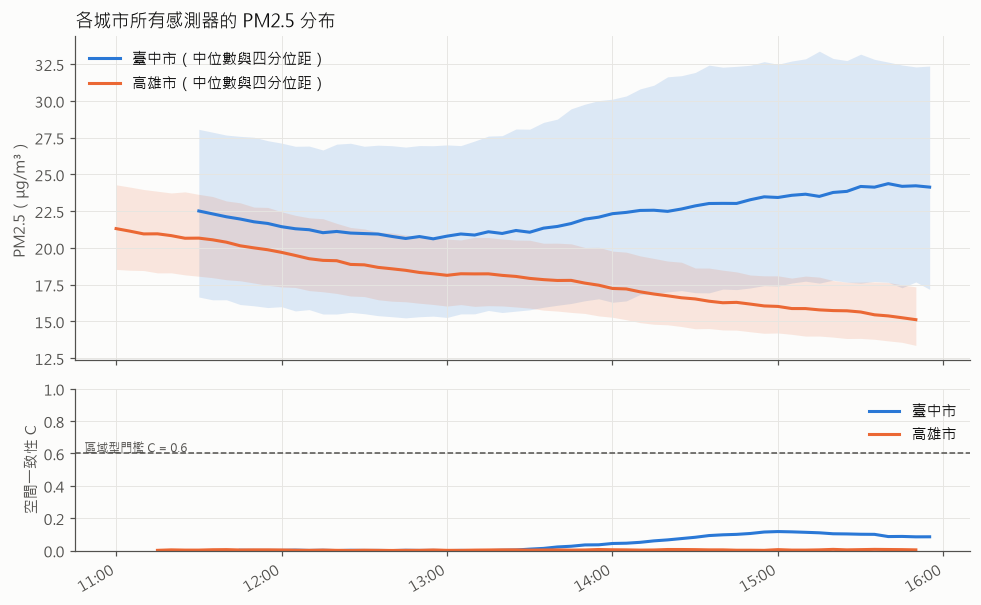

In [3]:
res = {}
for c, d in raw.items():
    mx, st = sp.to_matrix(sp.usable(d)); base = sp.baseline(mx, P.baseline_hours)
    res[c] = dict(mx=mx, st=st, base=base, coh=sp.city_coherence(mx, base, P))

fig, axes = plt.subplots(2, 1, figsize=(9, 5.6), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
for c, color in zip(CITIES, (BLUE, ORANGE)):
    q = res[c]["mx"].quantile([0.25, 0.5, 0.75], axis=1).T
    axes[0].fill_between(q.index, q[0.25], q[0.75], color=color, alpha=0.15, linewidth=0)
    axes[0].plot(q.index, q[0.5], color=color, linewidth=2, label=f"{c}（中位數與四分位距）")
    axes[1].plot(res[c]["coh"].index, res[c]["coh"], color=color, linewidth=2, label=c)
axes[0].set_ylabel("PM2.5（μg/m³）"); axes[0].legend(frameon=False, loc="upper left")
axes[0].set_title("各城市所有感測器的 PM2.5 分布", loc="left", fontsize=12)
axes[1].axhline(P.coherence_high, color=INK2, linewidth=1, linestyle="--")
axes[1].annotate(f"區域型門檻 C = {P.coherence_high}", (0.01, P.coherence_high), xycoords=("axes fraction", "data"),
                 va="bottom", fontsize=8, color=INK2)
axes[1].set_ylim(0, 1); axes[1].set_ylabel("空間一致性 C"); axes[1].legend(frameon=False, loc="upper right")
[a.xaxis.set_major_formatter(HHMM) for a in fig.axes]; fig.autofmt_xdate(); fig.tight_layout(); fig.savefig(FIG / "t20_fig1_city_overview.png", dpi=160)
{c: round(float(r["coh"].max()), 3) for c, r in res.items()}

## 3. 每個感測器的型態：局部事件、單點飆高、持續性偏高

,臺中市,高雄市
pattern,,
local_event,119,57
single_spike,9,43
persistent_high,73,4
above_background,241,158


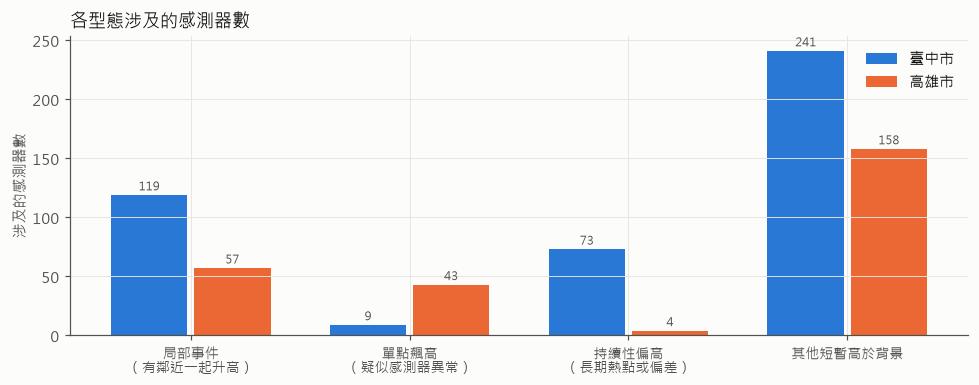

In [4]:
labels = {c: sp.label_station_events(sp.station_excess(r["mx"], r["st"], P), r["base"], P) for c, r in res.items()}
order = ["local_event", "single_spike", "persistent_high", "above_background"]
names = {"local_event": "局部事件\n（有鄰近一起升高）", "single_spike": "單點飆高\n（疑似感測器異常）",
         "persistent_high": "持續性偏高\n（長期熱點或偏差）", "above_background": "其他短暫高於背景"}
counts = pd.DataFrame({c: l[l.pattern != "normal"].groupby("pattern")["station_id"].nunique()
                       .reindex(order).fillna(0).astype(int) for c, l in labels.items()})
fig, ax = plt.subplots(figsize=(9, 3.6))
x = np.arange(len(order)); w = 0.38
for i, (c, color) in enumerate(zip(CITIES, (BLUE, ORANGE))):
    bars = ax.bar(x + (i - 0.5) * w, counts[c], width=w - 0.03, color=color, label=c)
    ax.bar_label(bars, fontsize=8, color=INK2, padding=2)
ax.set_xticks(x, [names[o] for o in order], fontsize=9); ax.set_ylabel("涉及的感測器數")
ax.set_title("各型態涉及的感測器數", loc="left", fontsize=12); ax.legend(frameon=False)
fig.tight_layout(); fig.savefig(FIG / "t20_fig2_patterns.png", dpi=160)
counts

## 4. 案例：臺中市的局部型群聚事件

In [5]:
c = "臺中市"; r = res[c]; lab = labels[c]
ev = lab[lab.pattern == "local_event"]
peak_t = ev.groupby("time").size().idxmax()
ids = ev[ev.time == peak_t].station_id.unique()
lat0, lon0 = r["st"].loc[ids, "lat"].median(), r["st"].loc[ids, "lon"].median()
P2 = sp.Params(r_sub_km=None)  # 原本的兩層尺度（2 km／15 km），第 7 節再和三層比較
series = pd.DataFrame([sp.metrics_at(r["mx"], r["st"], r["base"], t, lat0, lon0, P) for t in r["mx"].index]).set_index("time")
series["type"] = [sp.classify(m, P2) for m in series.reset_index().to_dict("records")]
series["type3"] = [sp.classify(m, P) for m in series.reset_index().to_dict("records")]
print(f"高峰時間 {peak_t:%H:%M}，事件感測器 {len(ids)} 個，中心 ({lat0:.4f}, {lon0:.4f})")
series.loc[[peak_t], ["n_region", "n_local", "B", "L", "E", "C", "n_local_elevated", "C_sub", "C_ring", "type", "type3"]].round(2)

高峰時間 14:40，事件感測器 59 個，中心 (24.2369, 120.5373)


,n_region,n_local,B,L,E,C,n_local_elevated,C_sub,C_ring,type,type3
time,,,,,,,,,,,
2026-10-19 14:40:00+08:00,509,34,23.49,35.33,11.84,0.19,21,0.4,0.04,local,subregional


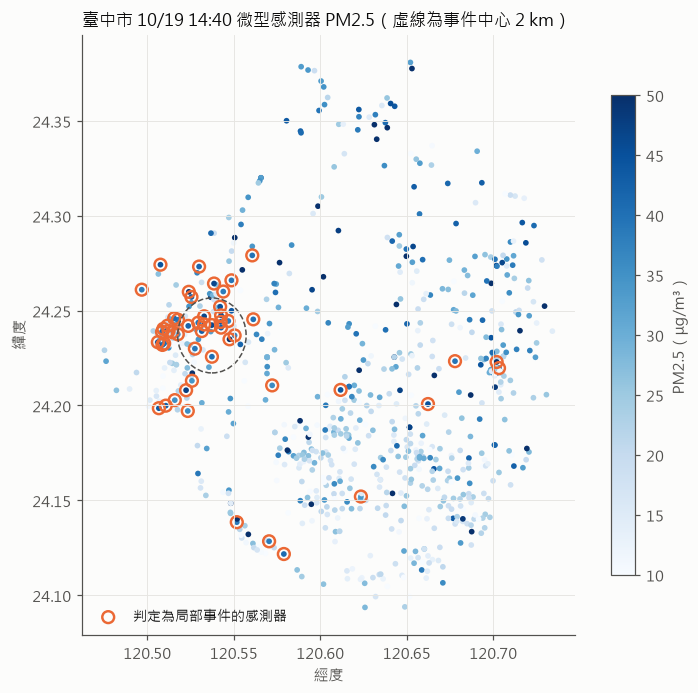

In [6]:
snap = lab[lab.time == peak_t].set_index("station_id").join(r["st"])
d = sp.haversine_km(lat0, lon0, snap["lat"].values, snap["lon"].values); snap = snap[d <= 20]
fig, ax = plt.subplots(figsize=(7.2, 6.4))
sc = ax.scatter(snap["lon"], snap["lat"], c=snap["pm25"], cmap="Blues", vmin=10, vmax=50, s=14, linewidths=0)
ev_now = snap[snap.pattern == "local_event"]
ax.scatter(ev_now["lon"], ev_now["lat"], facecolors="none", edgecolors=ORANGE, s=60, linewidths=1.6,
           label="判定為局部事件的感測器")
r_deg = 2 / (111 * np.cos(np.radians(lat0)))
ax.add_patch(plt.Circle((lon0, lat0), r_deg, fill=False, color=INK2, linestyle="--", linewidth=1))
ax.set_aspect(1 / np.cos(np.radians(lat0)))
cb = fig.colorbar(sc, ax=ax, shrink=0.8); cb.set_label("PM2.5（μg/m³）")
ax.set_xlabel("經度"); ax.set_ylabel("緯度"); ax.legend(frameon=False, loc="lower left", fontsize=9)
ax.set_title(f"臺中市 {peak_t:%m/%d %H:%M} 微型感測器 PM2.5（虛線為事件中心 2 km）", loc="left", fontsize=11)
fig.tight_layout(); fig.savefig(FIG / "t20_fig3_taichung_event_map.png", dpi=160)

type = local：11 個時段，14:30～15:20
type3 = subregional：15 個時段，14:25～15:35


,兩層（2/15 km）,三層（2/8/15 km）
insufficient_data,3,3
local,11,0
no_clear_event,40,36
subregional,0,15


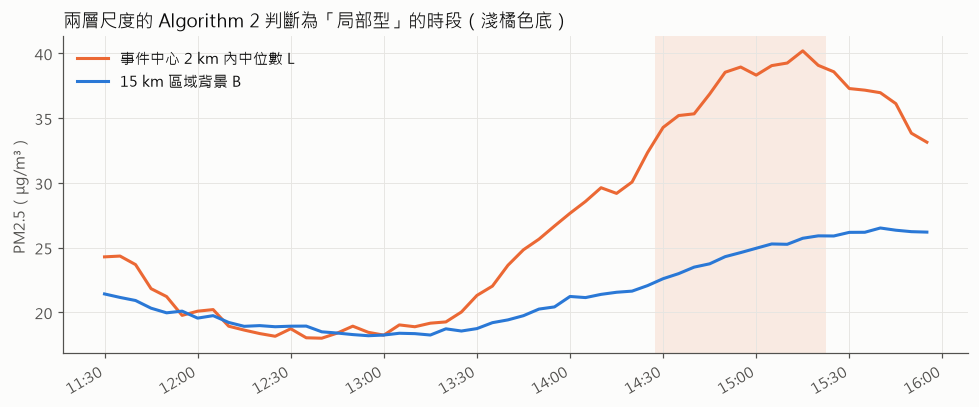

In [7]:
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(series.index, series["L"], color=ORANGE, linewidth=2, label="事件中心 2 km 內中位數 L")
ax.plot(series.index, series["B"], color=BLUE, linewidth=2, label="15 km 區域背景 B")
for t in series.index[series["type"] == sp.LOCAL]:
    ax.axvspan(t - pd.Timedelta("2.5min"), t + pd.Timedelta("2.5min"), color=ORANGE, alpha=0.12, linewidth=0)
ax.set_ylabel("PM2.5（μg/m³）"); ax.legend(frameon=False, loc="upper left")
ax.set_title("兩層尺度的 Algorithm 2 判斷為「局部型」的時段（淺橘色底）", loc="left", fontsize=12)
[a.xaxis.set_major_formatter(HHMM) for a in fig.axes]; fig.autofmt_xdate(); fig.tight_layout(); fig.savefig(FIG / "t20_fig4_taichung_event_timeseries.png", dpi=160)
for col, k in (("type", sp.LOCAL), ("type3", sp.SUBREGIONAL)):
    tt = series.index[series[col] == k]
    if len(tt): print(f"{col} = {k}：{len(tt)} 個時段，{tt.min():%H:%M}～{tt.max():%H:%M}")
pd.DataFrame({"兩層（2/15 km）": series["type"].value_counts(), "三層（2/8/15 km）": series["type3"].value_counts()}).fillna(0).astype(int)

## 5. 單點飆高：為什麼要求鄰近感測器一起升高

n        peak
city station_id                 
臺中市  12255641330   3  177.342000
高雄市  9031226244    1  128.313770
臺中市  12132088976  10  111.260000
高雄市  9110552166    2   94.400627
     9084163747    7   90.444285

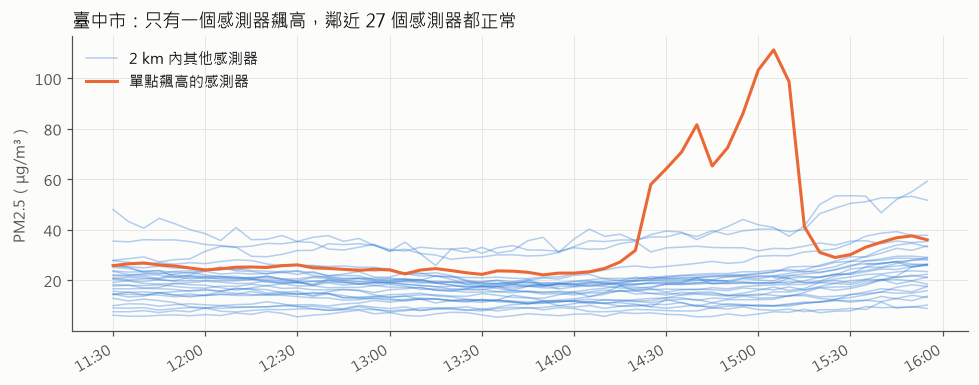

In [8]:
spikes = pd.concat([l.assign(city=c) for c, l in labels.items()])
spikes = spikes[spikes.pattern == "single_spike"]
top = spikes.groupby(["city", "station_id"]).agg(n=("time", "count"), peak=("pm25", "max")).sort_values("peak", ascending=False)
c, sid = top[top.n >= 6].index[0]; r = res[c]  # 持續 30 分鐘以上的單點飆高中，峰值最高的一個
lat, lon = r["st"].loc[sid, ["lat", "lon"]]
dist = pd.Series(sp.haversine_km(lat, lon, r["st"]["lat"].values, r["st"]["lon"].values), index=r["st"].index)
near = dist[(dist <= P.r_local_km) & (dist > 0)].index
fig, ax = plt.subplots(figsize=(9, 3.6))
for i, n in enumerate(near):
    ax.plot(r["mx"].index, r["mx"][n], color=BLUE, alpha=0.35, linewidth=1, label="2 km 內其他感測器" if i == 0 else None)
ax.plot(r["mx"].index, r["mx"][sid], color=ORANGE, linewidth=2, label="單點飆高的感測器")
ax.set_ylabel("PM2.5（μg/m³）"); ax.legend(frameon=False, loc="upper left")
ax.set_title(f"{c}：只有一個感測器飆高，鄰近 {len(near)} 個感測器都正常", loc="left", fontsize=12)
[a.xaxis.set_major_formatter(HHMM) for a in fig.axes]; fig.autofmt_xdate(); fig.tight_layout(); fig.savefig(FIG / "t20_fig5_single_spike.png", dpi=160)
top.head(5)

## 6. 濕度與微型感測器讀數

,median,count,city
rh_bin,,,
"(0, 50]",22.568667,3286,臺中市
"(50, 60]",23.802000,829,臺中市
"(60, 70]",23.398000,1090,臺中市
"(70, 80]",23.066000,1115,臺中市
"(80, 90]",23.972000,1833,臺中市
"(90, 100]",21.778000,40687,臺中市
"(0, 50]",18.813722,4493,高雄市
"(50, 60]",18.218940,35265,高雄市
"(60, 70]",17.506393,33383,高雄市


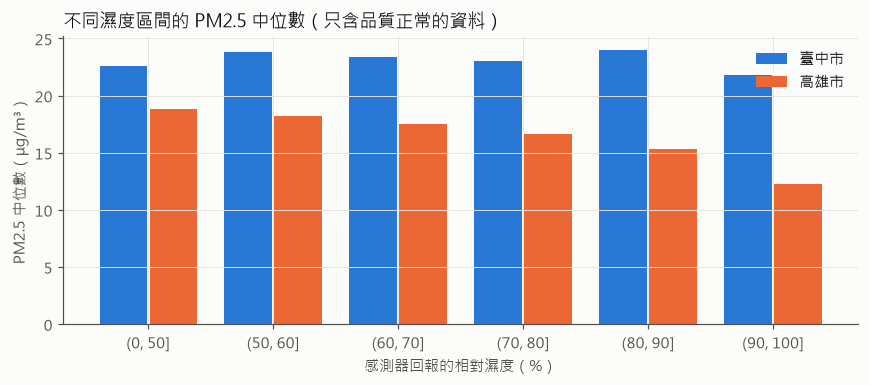

In [9]:
rows = []
for c, d in raw.items():
    f = quality.flag(d); f = f[f.qc_flag == "ok"].copy()
    f["rh_bin"] = pd.cut(f["rh"], [0, 50, 60, 70, 80, 90, 100])
    g = f.groupby("rh_bin", observed=True)["pm25"].agg(["median", "count"]); g["city"] = c
    rows.append(g)
rh = pd.concat(rows)
bins = list(dict.fromkeys(rh.index))
fig, ax = plt.subplots(figsize=(8, 3.6))
for c, color, off in zip(CITIES, (BLUE, ORANGE), (-0.2, 0.2)):
    g = rh[rh.city == c].reindex(bins)
    ax.bar(np.arange(len(bins)) + off, g["median"], width=0.38, color=color, label=c)
ax.set_xticks(np.arange(len(bins)), [str(b) for b in bins])
ax.set_xlabel("感測器回報的相對濕度（%）"); ax.set_ylabel("PM2.5 中位數（μg/m³）")
ax.set_title("不同濕度區間的 PM2.5 中位數（只含品質正常的資料）", loc="left", fontsize=12)
ax.legend(frameon=False); fig.tight_layout(); fig.savefig(FIG / "t20_fig6_humidity.png", dpi=160)
rh

## 7. 多尺度：加入 8 km 次區域尺度

同一個事件中心，比較 2 km、8 km、15 km 內「比自己基準升高 50%」的感測器比例，以及 8～15 km 外環的比例。
次區域型的條件（`spatial.is_subregional`）：C_sub ≥ 0.3、外環 C_ring < 0.3、15 km 的 C < 0.6，只沿用既有的兩個一致性門檻。

,0–2 km,2–5 km,5–8 km,8–15 km,15–30 km
time,,,,,
2026-10-19 11:30:00+08:00,NaN,NaN,NaN,NaN,NaN
2026-10-19 12:00:00+08:00,0.0,0.0,0.0,0.003344,0.0
2026-10-19 12:30:00+08:00,0.0,0.0,0.0,0.0,0.001669
2026-10-19 13:00:00+08:00,0.0,0.0,0.0,0.0,0.0
2026-10-19 13:30:00+08:00,0.0,0.015267,0.088889,0.010101,0.001681
2026-10-19 14:00:00+08:00,0.147059,0.242424,0.088889,0.010135,0.008389
2026-10-19 14:30:00+08:00,0.411765,0.343511,0.266667,0.037162,0.016722
2026-10-19 15:00:00+08:00,0.588235,0.484615,0.311111,0.054054,0.030252
2026-10-19 15:30:00+08:00,0.333333,0.305344,0.311111,0.120401,0.020101


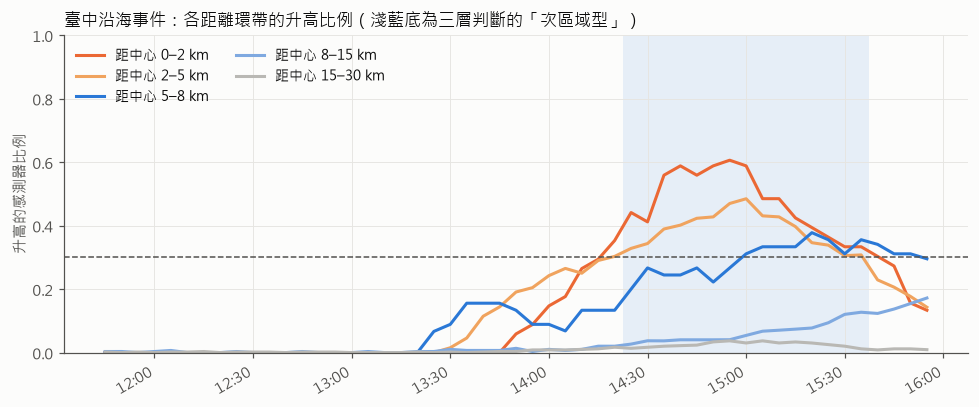

In [10]:
r = res["臺中市"]
dist = pd.Series(sp.haversine_km(lat0, lon0, r["st"]["lat"].values, r["st"]["lon"].values), index=r["st"].index)
rising = ((r["mx"] - r["base"]) / r["base"] > P.rise_ratio).where(r["mx"].notna() & r["base"].notna())
prof = pd.DataFrame({f"{a}–{b} km": rising.loc[:, (dist > a) & (dist <= b)].mean(axis=1)
                     for a, b in [(0, 2), (2, 5), (5, 8), (8, 15), (15, 30)]})
fig, ax = plt.subplots(figsize=(9, 3.8))
colors = ["#eb6834", "#f0a35e", "#2a78d6", "#7fa9e0", "#b9b8b4"]
for (name, col), color in zip(prof.items(), colors):
    ax.plot(prof.index, col, color=color, linewidth=2, label=f"距中心 {name}")
for t in series.index[series["type3"] == sp.SUBREGIONAL]:
    ax.axvspan(t - pd.Timedelta("2.5min"), t + pd.Timedelta("2.5min"), color=BLUE, alpha=0.10, linewidth=0)
ax.axhline(P.coherence_low, color=INK2, linewidth=1, linestyle="--")
ax.set_ylim(0, 1); ax.set_ylabel("升高的感測器比例"); ax.legend(frameon=False, loc="upper left", fontsize=9, ncol=2)
ax.set_title("臺中沿海事件：各距離環帶的升高比例（淺藍底為三層判斷的「次區域型」）", loc="left", fontsize=11)
[a.xaxis.set_major_formatter(HHMM) for a in fig.axes]; fig.autofmt_xdate(); fig.tight_layout(); fig.savefig(FIG / "t20_fig7_multiscale_profile.png", dpi=160)
prof.iloc[::6].round(2)

In [11]:
# 以每個感測器為中心掃描整個城市：哪些位置、哪些時段符合次區域型
scan = {}
for c, r in res.items():
    sc = sp.coherence_scan(r["mx"], r["st"], r["base"], P)
    flag = pd.DataFrame(sp.is_subregional(sc["C"], sc["C_sub"], sc["C_ring"], sc["n_sub"], P),
                        index=r["mx"].index, columns=r["mx"].columns)
    scan[c] = dict(sc=sc, flag=flag)
pd.DataFrame({c: {"時段數": len(v["flag"]), "有次區域型中心的時段": int(v["flag"].any(axis=1).sum()),
                  "曾被判為次區域型中心的感測器": int(v["flag"].any(axis=0).sum()),
                  "C_sub 最大值": round(float(np.nanmax(v["sc"]["C_sub"].values)), 2)} for c, v in scan.items()})

,臺中市,高雄市
時段數,54.00,59.00
有次區域型中心的時段,22.00,0.00
曾被判為次區域型中心的感測器,218.00,0.00
C_sub 最大值,0.57,0.07


15:00 有 187 個中心符合；緯度 24.177～24.303，經度 120.475～120.582


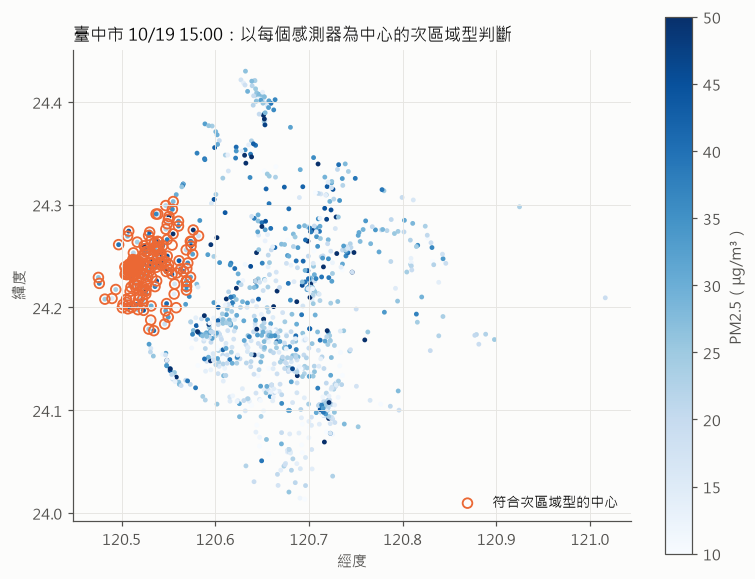

In [12]:
c = "臺中市"; r = res[c]; flag = scan[c]["flag"]
t_star = flag.sum(axis=1).idxmax()
st_now = r["st"].assign(pm25=r["mx"].loc[t_star], sub=flag.loc[t_star])
fig, ax = plt.subplots(figsize=(7.2, 6.4))
sc_ = ax.scatter(st_now["lon"], st_now["lat"], c=st_now["pm25"], cmap="Blues", vmin=10, vmax=50, s=10, linewidths=0)
on = st_now[st_now["sub"]]
ax.scatter(on["lon"], on["lat"], facecolors="none", edgecolors=ORANGE, s=40, linewidths=1.2, label="符合次區域型的中心")
ax.set_aspect(1 / np.cos(np.radians(lat0)))
cb = fig.colorbar(sc_, ax=ax, shrink=0.8); cb.set_label("PM2.5（μg/m³）")
ax.set_xlabel("經度"); ax.set_ylabel("緯度"); ax.legend(frameon=False, loc="lower right", fontsize=9)
ax.set_title(f"臺中市 {t_star:%m/%d %H:%M}：以每個感測器為中心的次區域型判斷", loc="left", fontsize=11)
fig.tight_layout(); fig.savefig(FIG / "t20_fig8_subregional_map.png", dpi=160)
print(f"{t_star:%H:%M} 有 {len(on)} 個中心符合；緯度 {on.lat.min():.3f}～{on.lat.max():.3f}，經度 {on.lon.min():.3f}～{on.lon.max():.3f}")

## 8. 門檻敏感度：區域型 C ≥ 0.6

這段資料沒有區域型事件，所以只能檢查「放寬門檻會不會誤報」：把升高門檻（rise）從 50% 降到 30%、20%，
看 15 km 內一致性 C 會不會超過區域型門檻。

In [13]:
rows = []
for c, r in res.items():
    for rr in (0.5, 0.3, 0.2):
        Pr = sp.Params(rise_ratio=rr)
        C = sp.coherence_scan(r["mx"], r["st"], r["base"], Pr)["C"].to_numpy()
        row = {"城市": c, "升高門檻": f"{rr:.0%}", "全市 C 最大": round(float(sp.city_coherence(r["mx"], r["base"], Pr).max()), 3),
               "15 km C 最大": round(float(np.nanmax(C)), 3)}
        for th in (0.6, 0.5, 0.4, 0.3):
            row[f"C≥{th} 的時段"] = int((np.nan_to_num(C) >= th).any(axis=1).sum())
        rows.append(row)
pd.DataFrame(rows)

,城市,升高門檻,全市 C 最大,15 km C 最大,C≥0.6 的時段,C≥0.5 的時段,C≥0.4 的時段,C≥0.3 的時段
0,臺中市,50%,0.117,0.341,0,0,0,9
1,臺中市,30%,0.253,0.611,1,14,21,24
2,臺中市,20%,0.384,0.745,18,22,25,28
3,高雄市,50%,0.007,0.023,0,0,0,0
4,高雄市,30%,0.014,0.167,0,0,0,0
5,高雄市,20%,0.029,0.167,0,0,0,0


## 9. 小結

文字結論整理在 `coordination/reports/T-20.md`。資料只涵蓋 2026-10-19 一個下午，**不能**據此校準區域型門檻；累積多天後重跑本 notebook。